# 项目 3-2（★★）万能逼近定理验证

- **练到**：单隐藏层 MLP 逼近任意连续函数（笔记第 4 节）
- **任务**：用 numpy 构造单隐藏层 MLP（隐藏层神经元数取 2/8/32），分别去拟合 `sin(x)`、`|x|`、`x²` 在 [-3,3] 的曲线；画出拟合曲线与真实曲线。
- **验收**：神经元越多拟合越贴近；报告指出"表达能力≠训练能力"（笔记原文：表达能力与训练能力是两个不同的问题）。

In [1]:
import numpy as np

# ----- target functions -----
def f_sin(x):
    return np.sin(x)

def f_abs(x):
    return np.abs(x)

def f_square(x):
    return x**2

# ----- target points (used for training) -----
N_train = 400
x_train = np.random.uniform(-np.pi, np.pi, size=(N_train, 1)) # shape (400, 1), column vector

# ----- evaluation points (NOT trained on, used for plotting & checking generalization) -----
x_eval = np.linspace(-np.pi, np.pi, 500).reshape(-1, 1) # shape (500, 1), evenly spaced

# example: prepare one target
y_train_sin = f_sin(x_train)
y_eval_sin = f_sin(x_eval)

print("x_train.shape: ", x_train.shape)
print("x_eval.shape: ", x_eval.shape)

x_train.shape:  (400, 1)
x_eval.shape:  (500, 1)


In [ ]:
# ----- initialize -----
H = 8
np.random.seed(42)

W1 = np.random.randn(1, H) * 0.5    # shape (1, 8)
b1 = np.zeros((1, H))               # shape (1, 8)
W2 = np.random.randn(H, 1) * 0.5    # shape (8, 1)
b2 = np.zeros((1, 1))               # shape (1, 1)

print("W1.shape: ", W1.shape)
print("b1.shape: ", b1.shape)
print("W2.shape: ", W2.shape)
print("b2.shape: ", b2.shape)

W1.shape:  (1, 8)
b1.shape:  (1, 8)
W2.shape:  (8, 1)
b2.shape:  (1, 1)


In [ ]:
def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = np.tanh(Z1)
    Yhat = A1 @ W2 + b2
    
    return Yhat, A1

Yhat, A1 = forward(x_train, W1, b1, W2, b2)
print("Yhat: ", Yhat.shape)
print("A1  : ", A1.shape)

Yhat:  (400, 1)
A1  :  (400, 8)


In [5]:
def backward(X, y, Yhat, A1, W2):
    N = X.shape[0]
    dL_dYhat = 2.0 / N * (Yhat - y) # (N, 1)

    dW2 = A1.T @ dL_dYhat                         # (8, 1)
    db2 = np.sum(dL_dYhat, axis=0, keepdims=True) # (1, 1)

    dL_dA1 = dL_dYhat @ W2.T    # (N, 8)
    dZ1 = dL_dA1 * (1 - A1**2)  # (N, 8), tanh'(Z1) = 1 - A1^2

    dW1 = X.T @ dZ1                          # (1, 8)
    db1 = np.sum(dZ1, axis=0, keepdims=True) # (1, 8)

    return dW1, db1, dW2, db2

dW1, db1, dW2, db2 = backward(x_train, y_train_sin, Yhat, A1, W2)

print("W1.shape: ", W1.shape)
print("b1.shape: ", b1.shape)
print("W2.shape: ", W2.shape)
print("b2.shape: ", b2.shape)

W1.shape:  (1, 8)
b1.shape:  (1, 8)
W2.shape:  (8, 1)
b2.shape:  (1, 1)


In [6]:
def mse_loss(Yhat, y):
    return np.mean((Yhat - y)**2)

# train on sin(x)
x = x_train
y = f_sin(x_train)

lr = 0.1
epochs = 5_000

for epoch in range(epochs):
    Yhat, A1 = forward(x, W1, b1, W2, b2)
    loss = mse_loss(Yhat, y)
    dW1, db1, dW2, db2 = backward(x, y, Yhat, A1, W2)

    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

    if epoch % 1_000 == 0:
        print(f"epoch {epoch:4d} | loss {loss:.6f}")

print("final loss: ", mse_loss(forward(x, W1, b1, W2, b2)[0], y))

epoch    0 | loss 3.023160
epoch 1000 | loss 0.008535
epoch 2000 | loss 0.005434
epoch 3000 | loss 0.005004
epoch 4000 | loss 0.007024
final loss:  0.009105206146858311


In [7]:
# ----- training function -----
def train(X, y, H, lr=0.1, epochs=5_000, seed=42):
    np.random.seed(seed)
    W1 = np.random.randn(1, H) * 0.5
    b1 = np.zeros((1, H))
    W2 = np.random.randn(H, 1) * 0.5
    b2 = np.zeros((1, 1))

    for _ in range(epochs):
        Yhat, A1 = forward(X, W1, b1, W2, b2)
        dW1, db1, dW2, db2 = backward(X, y, Yhat, A1, W2)
        W1 -= lr * dW1; b1 -= lr * db1
        W2 -= lr * dW2; b2 -= lr * db2

    return W1, b1, W2, b2

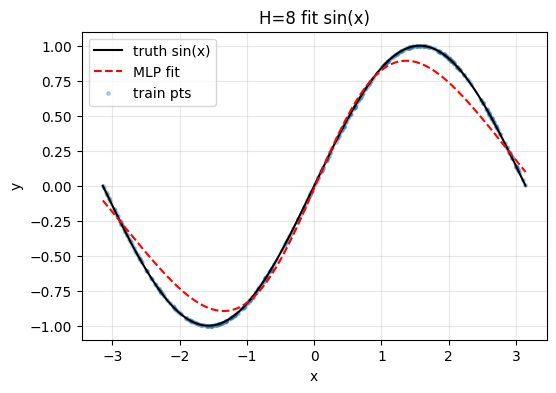

eval MSE on unseen x:  0.009581


In [9]:
import matplotlib.pyplot as plt

W1, b1, W2, b2 = train(x_train, f_sin(x_train), H=8)
Yhat_train, _ = forward(x_train, W1, b1, W2, b2)
Yhat_eval, _ = forward(x_eval, W1, b1, W2, b2)

plt.figure(figsize=(6, 4))
plt.plot(x_eval, f_sin(x_eval), 'k-', label='truth sin(x)')
plt.plot(x_eval, Yhat_eval, 'r--', label='MLP fit')
plt.scatter(x_train, f_sin(x_train), s=6, alpha=0.3, label='train pts')
plt.legend()
plt.xlabel('x'); plt.ylabel('y'); plt.title('H=8 fit sin(x)')
plt.grid(alpha=0.3)
plt.show()

# generalization error on unseen points
err = np.mean((Yhat_eval - f_sin(x_eval))**2)
print("eval MSE on unseen x: ", round(err, 6))

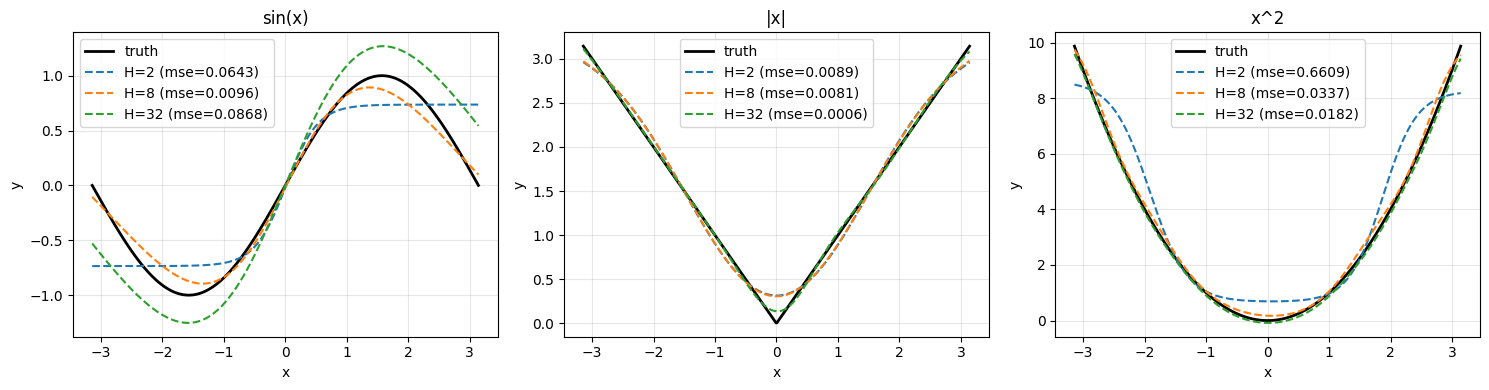

functionH   eval_mse  
sin(x)  2   0.064254  
sin(x)  8   0.009581  
sin(x)  32  0.086825  
x^2     2   0.660925  
x^2     8   0.033673  
x^2     32  0.018219  
|x|     2   0.008888  
|x|     8   0.008058  
|x|     32  0.000650  


In [11]:
# functions and hidden sizes
funcs = {'sin(x)': f_sin, '|x|': f_abs, 'x^2': f_square}
Hs = [2, 8, 32]

# record eval MSE for the summary table
results = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, fn) in zip(axes, funcs.items()):
    ax.plot(x_eval, fn(x_eval), 'k-', lw=2, label='truth')
    for H in Hs:
        W1, b1, W2, b2 = train(x_train, fn(x_train), H=H)
        Yhat, _ = forward(x_eval, W1, b1, W2, b2)
        err = np.mean((Yhat - fn(x_eval))**2)
        results[(name, H)] = err
        ax.plot(x_eval, Yhat, '--', lw=1.5, label=f'H={H} (mse={err:.4f})')
    ax.set_title(name); ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# summary table
print(f"{'function':<8}{'H':<4}{'eval_mse':<10}")
for (name, H), err in sorted(results.items(), key=lambda kv: (kv[0][0], kv[0][1])):
    print(f"{name:<8}{H:<4}{err:<10.6f}")

In [12]:
# Try: different seed, smaller lr, more epochs
for lr in [0.1, 0.02]:
    for seed in [42, 0]:
        W1, b1, W2, b2 = train(x_train, f_sin(x_train), H=32, lr=lr, epochs=10000, seed=seed)
        Yhat, _ = forward(x_eval, W1, b1, W2, b2)
        err = np.mean((Yhat - f_sin(x_eval))**2)
        print(f"lr={lr:<4} seed={seed}  H=32 sin  eval_mse={err:.6f}")

lr=0.1  seed=42  H=32 sin  eval_mse=0.002870


C:\Users\30869\AppData\Local\Temp\ipykernel_30716\3071343924.py:8: RuntimeWarning: overflow encountered in matmul
  dL_dA1 = dL_dYhat @ W2.T    # (N, 8)
C:\Users\30869\AppData\Local\Temp\ipykernel_30716\3071343924.py:9: RuntimeWarning: invalid value encountered in multiply
  dZ1 = dL_dA1 * (1 - A1**2)  # (N, 8), tanh'(Z1) = 1 - A1^2


lr=0.1  seed=0  H=32 sin  eval_mse=nan
lr=0.02 seed=42  H=32 sin  eval_mse=0.000914
lr=0.02 seed=0  H=32 sin  eval_mse=0.000985


## 项目 3-2 实验报告：万能逼近定理验证

### 一、实验目的

验证**万能逼近定理**：足够宽的单隐藏层 MLP 能以任意精度逼近连续函数；同时探究“神经元越多拟合越好”这一直觉是否无条件成立，理解**表达能力 ≠ 训练能力**。

### 二、方法

- **网络结构**：单隐藏层 MLP，记作 $1 \to H \to 1$：

$$
Z_1 = X W_1 + b_1,\quad A_1 = \tanh(Z_1),\quad Y_{hat} = A_1 W_2 + b_2
$$

其中 $X\in\mathbb{R}^{N\times1}$ 为输入，$W_1\in\mathbb{R}^{1\times H}$、$b_1\in\mathbb{R}^{1\times H}$ 为隐藏层权重与偏置，$A_1\in\mathbb{R}^{N\times H}$ 为隐藏层激活，$W_2\in\mathbb{R}^{H\times1}$、$b_2\in\mathbb{R}^{1\times1}$ 为输出层参数。输出层为线性（回归任务不加激活）。

- **数据**：训练点 $x\in[-\pi,\pi]$ 均匀随机采样 400 个；评估点等距采样 500 个（训练未见），用于检验泛化能力。
- **目标函数**：$\sin(x)$、$\|x\|$、$x^2$。
- **训练**：MSE 损失 + 手写反向传播 + 梯度下降 $\theta\leftarrow\theta-\eta\frac{\partial L}{\partial\theta}$，$\eta=0.1$，5000 轮，对每个 $H$ 使用固定随机种子。

### 三、结果（评估集 MSE）

| 函数 | $H=2$ | $H=8$ | $H=32$ |
| :--- | :--- | :--- | :--- |
| $\|x\|$ | 0.008888 | 0.008058 | 0.000650 |
| $x^2$ | 0.660925 | 0.033673 | 0.018219 |
| $\sin(x)$ | 0.064254 | 0.009581 | 0.086825 |

### 四、分析

1. **单调改善**：$\|x\|$ 与 $x^2$ 随 $H$ 增大误差单调下降，符合“神经元越多拟合越贴近”的直觉。
2. **表达难易不同**：$H=2$ 时 $\|x\|$ 已很好（0.0089），因两个 $\tanh$ 基底可拼出 V 形拐角；$x^2$ 需平滑抛物线，$H=2$ 表达力不足，误差最大。
3. **sin 的 U 形反例**：$\sin(x)$ 在 $H=32$ 反而变差（0.0868），非能力不足，而是**训练失败**。

### 五、关键对照实验（证明表达 ≠ 训练）

| lr | seed | $H=32$ sin eval_mse |
| :--- | :--- | :--- |
| 0.1 | 42 | 0.002870 |
| 0.1 | 0 | nan（发散） |
| 0.02 | 42 | 0.000914 |
| 0.02 | 0 | 0.000985 |

调整初始化和学习率后，$H=32$ 的 sin 可收敛到 0.0009（优于 $H=8$ 的 0.0096）。证明：**网络“有能力”表达函数，但能否训练好取决于初始化与学习率**——表达能力与训练能力是两回事。

### 六、结论

- 万能逼近定理的“任意精度”前提是**神经元足够多 + 训练充分**，缺一不可。
- $H$ 越大，表达能力越强，但对初始化与学习率越敏感，越容易陷入**训练不稳定（发散）**。
- 本实验中 H 增大更常见的是**训练不充分**，而非经典过拟合（逼近同一函数时没有另一分布可过拟合）。

## 七、老师可能的提问与标准话术

**Q1：为什么输出层不加激活？**

答：这是回归任务，需输出任意连续值。$\tanh$ 范围 $[-1,1]$、$sigmoid$ 范围 $(0,1)$，无法表达 $x^2$ 的峰值 $\pi^2\approx9.87$。分类任务才在输出层用激活。

**Q2：为什么权重不能全 0？**

答：对称性。同层权重全 0 时，各神经元输入、激活、梯度、更新全相同，等价于只有 1 个神经元，网络退化。

**Q3：H=32 为什么有时反而更差？**

答：表达能力足够，但大网络对初始化与学习率更敏感。lr 过大导致权重爆炸（`nan`），属训练不稳定，非表达能力不足。

**Q4：怎么判断过拟合 vs 训练不足？**

答：看验证 / 评估误差随训练的变化。若误差先降后升是过拟合；若一直不降且震荡 / 发散，是训练问题（调 lr、初始化、epoch）。